# EDA датасета House Prices

## Ключевые находки:


## Получаем данные

In [79]:
import sys; sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from src.constants import TARGET
from src.utils import load_train_df, load_description

pd.set_option('display.max_columns', None)

В датасете всего 1460 строк (при 80 колонках признаков) - поэтому отложу 15% данных для тестового датафрейма, а для валидации в будущем буду использовать K-fold кросс-валидацию.
Получу train датафрейм без части, отложенной для теста.

In [ ]:
df = pd.read_csv("../data/raw/train.csv")
print(df.shape)
del df

df_train = load_train_df()
y_train = df_train[TARGET]
X_train = df_train.drop(columns=TARGET)

(1460, 81)


## Анализ структуры датасета, разметка признаков

In [43]:
df_train.columns

Index(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
       'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
       'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
       'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle',
       'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea',
       'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond',
       'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC',
       'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd',
       'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt',
       'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond',
       'PavedDrive', 'Wo

In [83]:
CONTINUOUS = ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', 
              '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 
              'ScreenPorch', 'PoolArea', 'MiscVal',]
COUNT = ['BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 
         'GarageCars',]
ORDINAL = ['OverallQual', 'OverallCond', 'ExterQual', 'ExterCond', 'LotShape', 'LandSlope', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 
           'HeatingQC', 'KitchenQual', 'FireplaceQu', 'BsmtFinType1', 'BsmtFinType2', 'Functional', 'GarageQual', 'GarageCond', 'GarageFinish', 
           'PavedDrive', 'PoolQC',
            ]
NOMINAL = ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 
           'Condition1', 'Condition2', 'BldgType', 'HouseStyle',  'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
           'Foundation', 'Heating', 'Electrical', 'GarageType',   
           'MiscFeature', 'SaleType', 'SaleCondition', 'Fence']
BINARY = ['CentralAir', ]
TIME = ['YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MoSold', 'YrSold']

В датасете много ординальных признаков, которые имеют тип str. Для деревьев подойдет препроцессить данные с помощью Ordinal Encoding, а для линейных моделей / нейронок можно заюзать One Hot Encoding.

In [30]:
print(load_description())

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

In [29]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 1241 entries, 985 to 1127
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1241 non-null   int64  
 1   MSZoning       1241 non-null   str    
 2   LotFrontage    1009 non-null   float64
 3   LotArea        1241 non-null   int64  
 4   Street         1241 non-null   str    
 5   Alley          79 non-null     str    
 6   LotShape       1241 non-null   str    
 7   LandContour    1241 non-null   str    
 8   Utilities      1241 non-null   str    
 9   LotConfig      1241 non-null   str    
 10  LandSlope      1241 non-null   str    
 11  Neighborhood   1241 non-null   str    
 12  Condition1     1241 non-null   str    
 13  Condition2     1241 non-null   str    
 14  BldgType       1241 non-null   str    
 15  HouseStyle     1241 non-null   str    
 16  OverallQual    1241 non-null   int64  
 17  OverallCond    1241 non-null   int64  
 18  YearBuilt      1241 no

Мысли
- MSSubClass - формат этажность с какими-то деталями + время постройки (которое мы и так знаем из других переменных - BldgType, HouseStyle). 
- MSZoning - полезный признак, к какой функциональной зоне относится проданный участок или здание и как его разрешено использовать по закону
- LotFrontage - интуитивно кажется - чем больше улицы примыкает, тем лучше, особенно в хороших районах. Полезно ли?
- LotArea / GrLivArea - полезные признаки - площадь участка и дома
- TotalBsmtSF - полезный признак - площадь подвала / цоколя
- Neighborhood - полезный признак, стоимость недвижимости должна зависеть от района, близкие дома с большей вероятностью стоят похоже
- OverallQual / OverallCond - полезный признак, стоимость материалов и состояние дома напрямую влияют на его стоимость
- ExterQual / ExterCond / BsmtQual / BsmtCond - возможно полезные признаки, но может он сильно скоррелирован с Overall
- YearBuilt / YearRemodAdd - можно ли всегда брать одно из них? Чем новее дом, тем больше его стоимость
- Foundation - может быть полезно (если некачественные материалы, то дом может стоить дешевле)
- BsmtFinType1 / BsmtFinSF1 - может быть полезно, ожидаю, что у многих домов есть basement
- GarageCars / GarageArea / GarageQual / GarageCond - может быть полезно
- Fence - может быть полезно?
- MiscVal - полезно, добавочная стоимость

[]

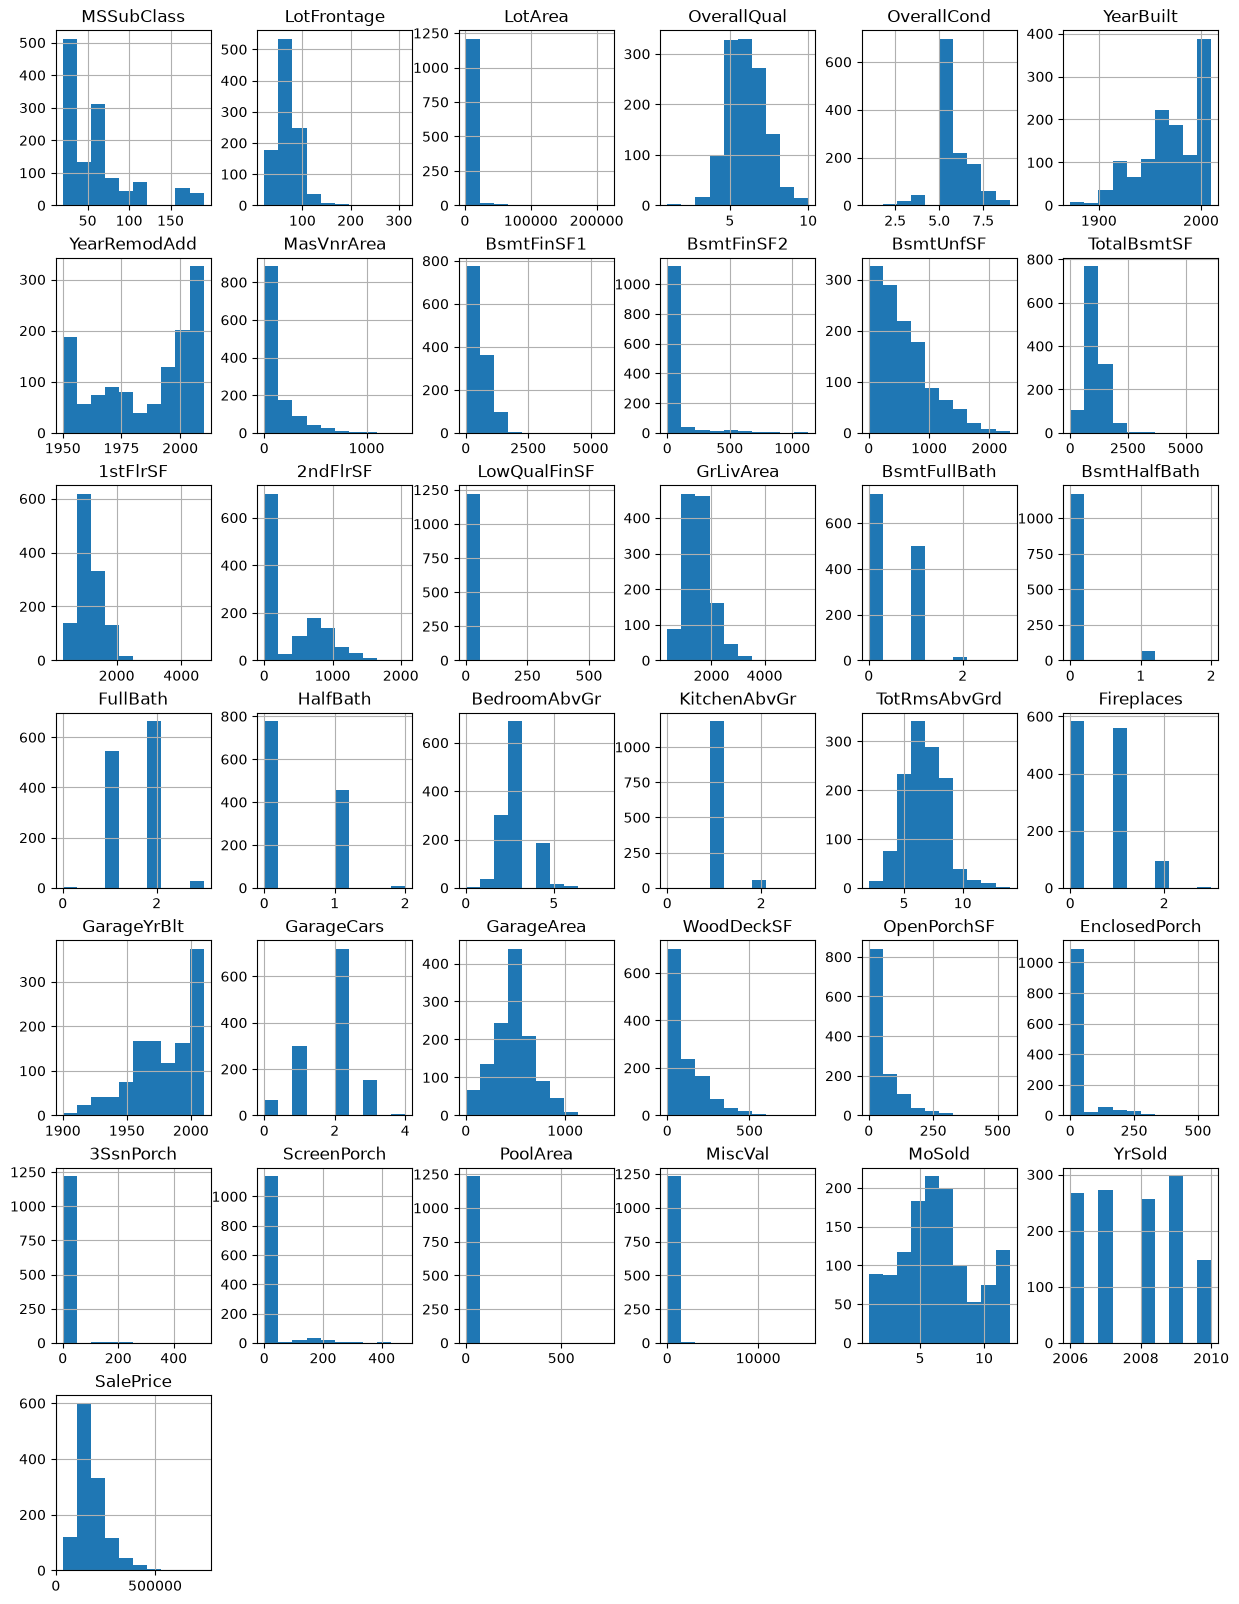

In [31]:
df_train.select_dtypes(include = ['float64', 'int64']).hist(figsize=(15, 20))
plt.plot()

Видим, что часть признаков имеет явные выбросы

In [63]:
str_cols = df_train.select_dtypes(include=['str']).columns

for col in str_cols:
    print(f"--- Колонка: {col} ---")
    counts = df_train[col].value_counts(dropna=False)
    shares = (df_train[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    summary = pd.DataFrame({
        'share_%': shares,
        'count': counts
    })
    print(summary)
    print("----------------\n")

--- Колонка: MSZoning ---
          share_%  count
MSZoning                
RL          79.13    982
RM          14.83    184
FV           4.35     54
RH           1.21     15
C (all)      0.48      6
----------------

--- Колонка: Street ---
        share_%  count
Street                
Pave      99.68   1237
Grvl       0.32      4
----------------

--- Колонка: Alley ---
       share_%  count
Alley                
NaN      93.63   1162
Grvl      3.79     47
Pave      2.58     32
----------------

--- Колонка: LotShape ---
          share_%  count
LotShape                
Reg         62.77    779
IR1         33.44    415
IR2          3.06     38
IR3          0.73      9
----------------

--- Колонка: LandContour ---
             share_%  count
LandContour                
Lvl            90.17   1119
Bnk             4.19     52
HLS             3.14     39
Low             2.50     31
----------------

--- Колонка: Utilities ---
           share_%  count
Utilities                
AllPub  

In [65]:
near_const = [c for c in X_train if X_train[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.95]
print("Почти константные признаки (>95% одно значение):")
for x in near_const:
    print(x)

Почти константные признаки (>95% одно значение):
Street
Utilities
Condition2
RoofMatl
Heating
LowQualFinSF
KitchenAbvGr
3SsnPorch
PoolArea
PoolQC
MiscFeature
MiscVal


## Таргет

В логарифмической шкале распределение цен выглядит похожим на нормальное распределение

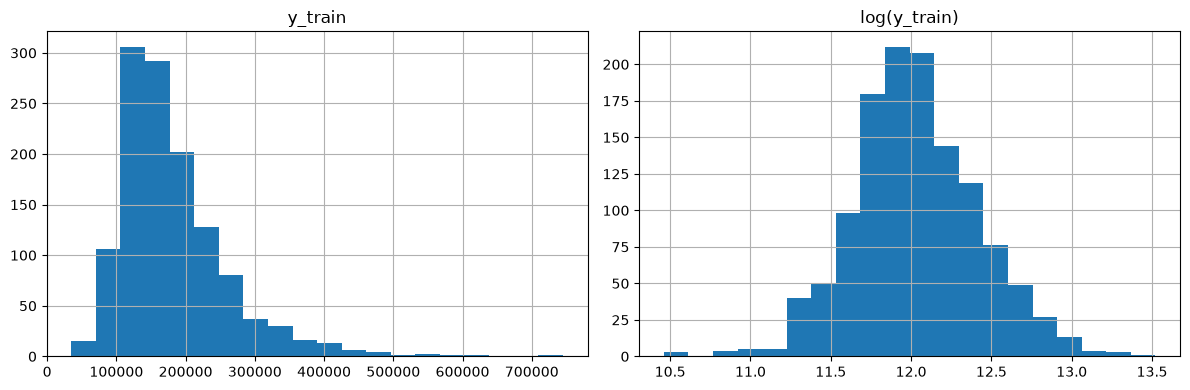

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y_train.hist(bins=20, ax=axes[0])
axes[0].set_title('y_train')
np.log(y_train).hist(bins=20, ax=axes[1])
axes[1].set_title('log(y_train)')
plt.tight_layout()
plt.show()

Посмотрим и сравним самый дорогой и самый дешевый дома

In [80]:

df_train[df_train[TARGET] == max(y_train)]

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NoRidge,Norm,Norm,1Fam,2Story,10,5,1996,1996,Hip,CompShg,Wd Sdng,ImStucc,NaN,0.0,Gd,TA,PConc,Ex,TA,Av,GLQ,2096,Unf,0,300,2396,GasA,Ex,Y,SBrkr,2411,2065,0,4476,1,0,3,1,4,1,Ex,10,Typ,2,TA,Attchd,1996.0,Fin,3,813,TA,TA,Y,171,78,0,0,0,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000


In [81]:
df_train[df_train[TARGET] == min(y_train)]

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
496,30,C (all),60.0,7879,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,1Fam,1Story,4,5,1920,1950,Gable,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,495,Unf,0,225,720,GasA,TA,N,FuseA,720,0,0,720,0,0,1,0,2,1,TA,4,Typ,0,NaN,NaN,NaN,NaN,0,0,NaN,NaN,N,0,523,115,0,0,0,NaN,GdWo,NaN,0,11,2009,WD,Abnorml,34900


Во многих домах нет аллеи, бассейна, забора и камина. В некоторых домах нет гаража. Также много где пропущено поле LotFrontage (длина примыкающей улицы)

## Пропущенные значения

In [53]:
missing_count = df_train.isna().sum()
missing_count = missing_count[missing_count > 0]

pd.DataFrame({
    'count': missing_count,
    'share': (100 * missing_count / len(df_train)).round(1)
})

,count,share
LotFrontage,232,18.7
Alley,1162,93.6
MasVnrType,726,58.5
MasVnrArea,7,0.6
BsmtQual,31,2.5
BsmtCond,31,2.5
BsmtExposure,32,2.6
BsmtFinType1,31,2.5
BsmtFinType2,31,2.5
Electrical,1,0.1


В MasVnrType 726 пропусков. Посмотрю, что было в CSV до загрузки: по описанию данных None означает, что облицовки нет.

In [102]:
raw_type = pd.read_csv('../data/raw/train.csv', index_col='Id', keep_default_na=False)['MasVnrType']
raw_type.loc[df_train.index].value_counts()

MasVnrType
None       719
BrkFace    390
Stone      111
BrkCmn      14
NA           7
Name: count, dtype: int64

Из 726 пропусков 719 были записаны как None и только 7 как NA. Для модели сохраню «нет облицовки» отдельной категорией.
Семь домов с неизвестным типом оставлю в категории Unknown.

С гаражом и подвалом можно свериться по площади. Если площадь подвала равна нулю, пропуск BsmtQual означает отсутствие подвала.
Если площадь положительная, а характеристика пропущена, оставлю Unknown. Для GarageYrBlt год отсутствующего гаража сам по себе смысла не имеет. В baseline проще взять GarageCars и GarageArea.

У LotFrontage пропущено 232 значения. В EDA оставлю их как есть. В baseline заполню медианой, посчитанной на обучающей части каждого фолда. Для Electrical использую категорию Unknown.

## Data Quality

In [158]:
quality = pd.Series({
    "Дубликаты": df_train.duplicated().sum(),
    "Отрицательные признаки": (df_train.select_dtypes("number") < 0).any(axis=1).sum(),
    "Год продажи после года постройки": df_train[["YearBuilt"]].gt(df_train["YrSold"], axis=0).any(axis=1).sum(),
    "Год ренновации после года продажи": df_train[["YearRemodAdd"]].gt(df_train["YrSold"], axis=0).any(axis=1).sum(),
    "Ренновация до постройки": (df_train["YearRemodAdd"] < df_train["YearBuilt"]).sum(),
    "Жилая площадь != 1 этаж + 2 этаж + LowQual": (df_train["GrLivArea"] != df_train[["1stFlrSF", "2ndFlrSF", "LowQualFinSF"]].sum(axis=1)).sum(),
    "Площадь подвала != подвал 1 + подвал 2 + Unf": (df_train["TotalBsmtSF"] != df_train[["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"]].sum(axis=1)).sum(),
    "Площадь гаража>0, но качество гаража пропущено": ((df_train["GarageArea"] > 0) & df_train["GarageQual"].isna()).sum(),
    "Площадь подвала>0, но качество подвала пропущено": ((df_train["TotalBsmtSF"] > 0) & df_train["BsmtQual"].isna()).sum(),
    "Площадь бассейна>0, но качество бассейна пропущено": ((df_train["PoolArea"] > 0) & df_train["PoolQC"].isna()).sum(),
    "Площадь облицовки>0, но тип облицовка пропущен": ((df_train["MasVnrArea"] > 0) & df_train["MasVnrType"].isna()).sum(),
    "тип облицовки есть, но площадь облицовки=0": ((df_train["MasVnrArea"] == 0) & df_train["MasVnrType"].notna()).sum(),
})

quality[quality > 0]

Год ренновации после года продажи                 1
Площадь облицовки>0, но тип облицовка пропущен    5
тип облицовки есть, но площадь облицовки=0        2
dtype: int64

## Числовые признаки и цена

Вопросы:
1. Какие числовые признаки сильнее всего связаны с ценой?

2. Связь линейная или монотонная, но нелинейная?

3. Есть ли выбросы, которые исказят линейную модель?

4. Какие признаки почти всегда равны 0?


In [117]:
cols = CONTINUOUS + COUNT + ['OverallQual', 'OverallCond']
numerical = df_train[cols]
y_log = np.log(y_train)
corr = pd.DataFrame({
    'pearson': numerical.corrwith(y_log),
    'spearman': numerical.corrwith(y_log, method='spearman')
})
corr[(abs(corr['pearson']) >= 0.3) | (abs(corr['spearman']) >= 0.3)].round(2).sort_values(by='pearson', key=abs, ascending=False)

,pearson,spearman
OverallQual,0.81,0.80
GrLivArea,0.69,0.73
GarageCars,0.68,0.69
GarageArea,0.65,0.64
TotalBsmtSF,0.60,0.60
1stFlrSF,0.59,0.57
FullBath,0.59,0.63
TotRmsAbvGrd,0.52,0.53
Fireplaces,0.49,0.52
MasVnrArea,0.43,0.41


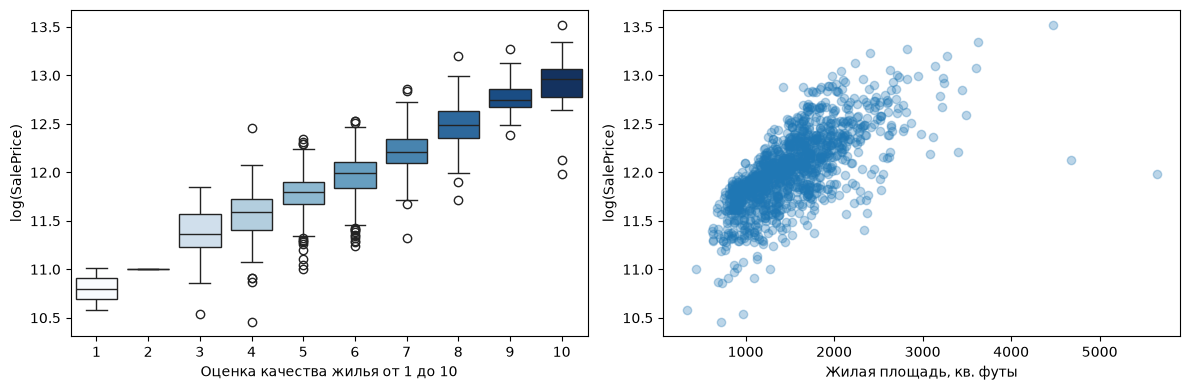

In [135]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

sns.boxplot(x=df_train['OverallQual'], y=y_log, ax=ax[0], hue=df_train['OverallQual'], legend=False, palette='Blues')
ax[0].set_xlabel('Оценка качества жилья от 1 до 10')
ax[0].set_ylabel('log(SalePrice)')

ax[1].scatter(df_train['GrLivArea'], y_log, alpha=0.3)
ax[1].set_xlabel('Жилая площадь, кв. футы')
ax[1].set_ylabel('log(SalePrice)')

plt.tight_layout()
plt.show()

In [119]:
df_train.nlargest(3, 'GrLivArea')[['GrLivArea', TARGET]]

,GrLivArea,SalePrice
Id,,
1299,5642,160000
524,4676,184750
1183,4476,745000


In [120]:
zero_share = 100 * numerical.eq(0).sum() / numerical.count()
zero_share[zero_share > 95].round(1)

LowQualFinSF    98.3
3SsnPorch       98.2
PoolArea        99.5
MiscVal         96.5
dtype: float64

Сильнее всего с ценой связаны OverallQual, GrLivArea и GarageCars. У GrLivArea корреляция Пирсона с log(цены) 0.69, Спирмена 0.73.
На графике цена в целом растёт с площадью, но по двум самым большим домам я бы сильно завысил прогноз, если бы смотрел только на площадь. 
Дома на 4676 и 5642 кв. фута продали за 184 750 и 160 000 долларов. Пока оставлю оба. 
Для линейной модели можно сравнить обучение с ними и без них на тех же фолдах, сохранив все дома в валидации.

PoolArea, LowQualFinSF, 3SsnPorch и MiscVal равны нулю более чем у 95% домов с известным значением. Например, для PoolArea это ожидаемо: у большинства домов просто нет бассейна.

## Категориальные признаки и цена

Проверю две идеи из начала EDA: зависит ли цена от района и растёт ли она с оценкой качества кухни. Рядом с медианой посмотрю число домов, особенно для редких районов.

In [136]:
prices = df_train.groupby('Neighborhood')[TARGET]
prices.agg(['count', 'median']).sort_values('median')

,count,median
Neighborhood,,
MeadowV,13,91000.0
BrDale,14,103000.0
IDOTRR,28,107250.0
OldTown,99,120000.0
BrkSide,47,121000.0
Edwards,92,121750.0
Blueste,1,124000.0
Sawyer,60,135000.0
SWISU,21,139500.0


In [137]:
prices = df_train.groupby('KitchenQual')[TARGET]
prices.agg(['count', 'median']).reindex(['Fa', 'TA', 'Gd', 'Ex'])

,count,median
KitchenQual,,
Fa,33,115000.0
TA,621,139000.0
Gd,504,200750.0
Ex,83,318000.0


В NAmes медиана 142 000 долларов по 190 домам, в NridgHt 315 000 по 65. В Blueste всего один дом. 
Проверю на одинаковых фолдах, насколько медиана по району выигрывает у общей медианы. Обе считаю только по обучающей части фолда.

У KitchenQual медианы идут по порядку: 115 000, 139 000, 200 750 и 318 000 долларов. Шаги между уровнями разные.
Для линейной модели сравню два варианта на тех же фолдах: отдельная категория для каждой оценки и одна шкала от 1 до 4.
Остальные признаки оставлю одинаковыми, сравню RMSE по log(цене).

Посмотрю ещё на фундамент, тип гаража и условия продажи. Особенно интересен гараж: есть ли разница между домами без гаража, с отдельно стоящим и с пристроенным гаражом?

In [141]:
for col in ['Foundation', 'GarageType', 'SaleCondition']:
    prices = df_train.groupby(col, dropna=False)[TARGET]
    print(prices.agg(['count', 'median']).sort_values('median'), '\n')

            count    median
Foundation                 
Slab           21   98000.0
BrkTil        122  125750.0
Stone           6  126500.0
CBlock        538  143000.0
Wood            3  164000.0
PConc         551  206000.0 

            count    median
GarageType                 
NaN            66   98950.0
CarPort         8  104900.0
Detchd        327  129500.0
Basment        17  153000.0
2Types          6  159000.0
Attchd        738  185000.0
BuiltIn        79  222500.0 

               count    median
SaleCondition                 
AdjLand            4  104000.0
Abnorml           85  135000.0
Family            18  147000.0
Normal          1019  162000.0
Alloca             8  166168.5
Partial          107  239799.0 



У домов с фундаментом PConc медиана 206 000 (551 дом), с CBlock — 143 000 (538 домов). Для Wood всего 3 дома.

У 66 домов без гаража медиана 98 950, с отдельно стоящим гаражом 129 500 (327 домов), с пристроенным 185 000 (738 домов). 
Интересно, добавит ли тип гаража что-то к модели, которая уже знает его площадь и число машиномест.

Для Partial медиана 239 799 (107 продаж), для Normal 162 000 (1019 продаж). По описанию Partial связан с продажей ещё не законченного дома. 
Тут различается и само жильё, поэтому разницу медиан нельзя приписать условиям сделки.

## Время

Хочется объединить YrSold и MoSold. В модели можно оставить месяц отдельно для проверки сезонности.
Посмотрю, как менялась медианная цена от месяца к месяцу.
Рядом построю число продаж: интересно, на скольких домах посчитана каждая точка.

In [147]:
sold = pd.to_datetime(dict(
    year=df_train['YrSold'], month=df_train['MoSold'], day=1
))
monthly = y_train.groupby(sold).agg(['count', 'median'])
print("Первая продажа в трейне: ", sold.min(), ", последняя продажа в трейне", sold.max())

Первая продажа в трейне:  2006-01-01 00:00:00 , последняя продажа в трейне 2010-07-01 00:00:00


В трейне данные о продажах с января 2006 по июль 2010 года. То есть кризис 2008 года включен в выборку.

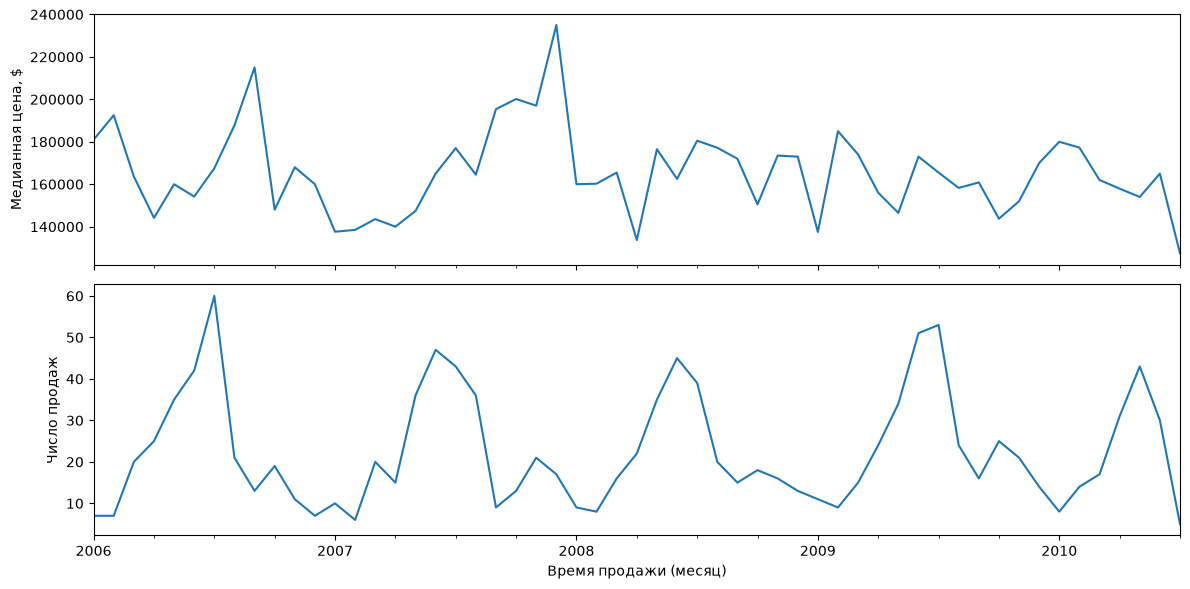

In [146]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
monthly['median'].plot(ax=ax[0])
ax[0].set_ylabel('Медианная цена, $')
monthly['count'].plot(ax=ax[1])
ax[1].set_ylabel('Число продаж')
ax[1].set_xlabel('Время продажи (месяц)')
plt.tight_layout()
plt.show()

Медиана цены очень волатильна во времени. По числу продаж видна сезонность - летом продается больше домов.

Посчитаю возраст дома на момент продажи. Отдельно посмотрю
на дома, у которых после постройки была реконструкция.

In [157]:
age = df_train['YrSold'] - df_train['YearBuilt']
remod = df_train['YearRemodAdd']
since_remod = (df_train['YrSold'] - remod).where(
    (remod > df_train['YearBuilt']) & (remod <= df_train['YrSold'])
)
remod_same_built = df_train[df_train['YearRemodAdd'] == df_train['YearBuilt']]
remod_before_built = df_train[df_train['YearRemodAdd'] < df_train['YearBuilt']]
remod_after_sold = df_train[df_train['YearRemodAdd'] > df_train['YrSold']]

print(len(remod_same_built), len(remod_before_built), len(remod_after_sold))

647 0 1


In [156]:
remod_after_sold

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
524,60,RL,130.0,40094,Pave,NaN,IR1,Bnk,AllPub,Inside,Gtl,Edwards,PosN,PosN,1Fam,2Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,Stone,762.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,2260,Unf,0,878,3138,GasA,Ex,Y,SBrkr,3138,1538,0,4676,1,0,3,1,3,1,Ex,11,Typ,1,Gd,BuiltIn,2007.0,Fin,3,884,TA,TA,Y,208,406,0,0,0,0,NaN,NaN,NaN,0,10,2007,New,Partial,184750


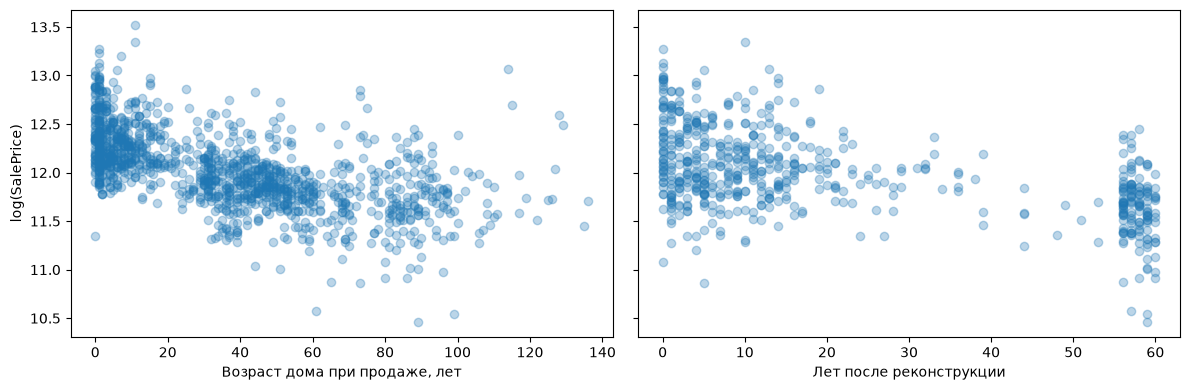

In [152]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax[0].scatter(age, y_log, alpha=0.3)
ax[0].set_xlabel('Возраст дома при продаже, лет')
ax[0].set_ylabel('log(SalePrice)')
ax[1].scatter(since_remod, y_log, alpha=0.3)
ax[1].set_xlabel('Лет после реконструкции')
plt.tight_layout()
plt.show()

In [150]:
years = pd.DataFrame({'age': age, 'since_remod': since_remod})
years = years.dropna()
print(len(years))
years.corrwith(y_log, method='spearman').round(2)

593


age           -0.64
since_remod   -0.48
dtype: float64

У 647 домов год реконструкции совпадает с годом постройки. Один дом был построен и продан 2007, а отремонтирован в 2008. На момент продажи эти работы ещё в будущем.
Это второй самый большой дом из раздела выше.

Осталось 593 дома с реконструкцией после постройки.
На этих домах корреляция Спирмена с ценой −0.64 для возраста и −0.48 для лет после работ. Проверю на линейном бейзлайне, добавляет ли срок после реконструкции что-то к возрасту дома.